# Bias vs Accuracy: Sweep over alpha and layer size

Este notebook entrena modelos con distintas combinaciones de:
- **alpha** (factor de penalización de fairness): `[0.0, 0.1, 0.5, 1.0, 5.0, 10.0]`
- **ls** (tamaño de la capa intermedia): `[32, 64, 128, 256, 512]`

Para cada combinación se calcula:
- **Accuracy global** en test
- **|TPR gap|** entre géneros (bias)

El gráfico final muestra el trade-off **Bias vs Accuracy**.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gc
import sys
from dotenv import load_dotenv

load_dotenv()
os.chdir(os.getenv("ROOT"))
sys.path.insert(0, os.getenv("ROOT"))

from src.experiment_notebook import setup_experiment, fine_tune_and_evaluate

## 1. Configuración del sweep

Ajusta los parámetros del sweep aquí. `epochs_per_iter` × `num_iterations` = epochs totales de entrenamiento por combinación.

In [2]:
# ========== Parámetros del sweep ==========
alphas = [0.1, 0.25, 0.5, 0.75]
layer_sizes = [8, 16, 32]

# Entrenamiento: epochs totales = epochs_per_iter * num_iterations
epochs_per_iter = 5    # epochs por iteración
num_iterations = 5     # número de iteraciones
batch_size = 32
lr = 1e-4
seed = 42

total_combos = len(alphas) * len(layer_sizes)
print(f"Total combinaciones: {total_combos}")
print(f"Epochs totales por combinación: {epochs_per_iter * num_iterations}")

Total combinaciones: 12
Epochs totales por combinación: 25


## 2. Entrenamiento del sweep

Se entrena un modelo para cada combinación (alpha, ls) y se guardan los resultados.

In [3]:
# Archivo para guardar resultados incrementalmente
RESULTS_FILE = 'sweep_results.json'

In [4]:
# Cargar resultados previos si existen (para poder resumir)
if os.path.exists(RESULTS_FILE):
    with open(RESULTS_FILE, 'r') as f:
        all_results = json.load(f)
    print(f"Cargados {len(all_results)} resultados previos")
else:
    all_results = []

# Conjunto de combinaciones ya completadas
done_keys = {(r['alpha'], r['ls']) for r in all_results}

combo_idx = 0
for alpha in alphas:
    for ls in layer_sizes:
        combo_idx += 1
        key = (alpha, ls)

        # Saltar si ya se completó esta combinación
        if key in done_keys:
            print(f"[{combo_idx}/{total_combos}] alpha={alpha}, ls={ls} — ya completado, saltando.")
            continue

        print(f"\n{'='*60}")
        print(f"[{combo_idx}/{total_combos}] alpha={alpha}, ls={ls}")
        print(f"{'='*60}")

        # Setup
        ctx = setup_experiment(
            alpha=alpha,
            prev2last_layer_size=ls,
            batch_size=batch_size,
            lr=lr,
            seed=seed
        )

        # Entrenar por iteraciones
        result_summary = None
        for i in range(num_iterations):
            print(f"  Iteración {i+1}/{num_iterations}")
            result_summary = fine_tune_and_evaluate(ctx, epochs=epochs_per_iter, alpha=alpha)

        # Extraer métricas de la última evaluación
        # result_summary = {'All': {...}, 'Male': {...}, 'Female': {...}, 'gender_pred': {...}}
        # Cada uno tiene: accuracy, auc, confusion_matrix [[TN,FP],[FN,TP]]
        acc_global = result_summary['All']['accuracy']

        # Calcular TPR por género: TPR = TP / (TP + FN)
        cm_male = result_summary['Male']['confusion_matrix']
        cm_female = result_summary['Female']['confusion_matrix']

        tpr_male = cm_male[1][1] / (cm_male[1][0] + cm_male[1][1]) if (cm_male[1][0] + cm_male[1][1]) > 0 else 0.0
        tpr_female = cm_female[1][1] / (cm_female[1][0] + cm_female[1][1]) if (cm_female[1][0] + cm_female[1][1]) > 0 else 0.0
        tpr_gap = abs(tpr_male - tpr_female)

        # AUC de predicción de género en la última capa (layer_6 = capa intermedia 'interm')
        gender_pred = result_summary.get('gender_pred', {})
        gender_auc_last = gender_pred.get('layer_6', {}).get('auc', None)

        entry = {
            'alpha': alpha,
            'ls': ls,
            'accuracy': acc_global,
            'tpr_male': tpr_male,
            'tpr_female': tpr_female,
            'tpr_gap': tpr_gap,
            'auc_all': result_summary['All']['auc'],
            'auc_male': result_summary['Male']['auc'],
            'auc_female': result_summary['Female']['auc'],
            'acc_male': result_summary['Male']['accuracy'],
            'acc_female': result_summary['Female']['accuracy'],
            'gender_auc_last_layer': gender_auc_last,
        }
        all_results.append(entry)

        # Guardar incrementalmente
        with open(RESULTS_FILE, 'w') as f:
            json.dump(all_results, f, indent=2)

        print(f"  => Accuracy: {acc_global:.3f}, |TPR gap|: {tpr_gap:.3f}, Gender AUC (last layer): {gender_auc_last:.3f}")

        # Liberar memoria GPU
        del ctx
        torch.cuda.empty_cache()
        gc.collect()

print(f"\nSweep finalizado. {len(all_results)} resultados guardados en {RESULTS_FILE}")

Cargados 6 resultados previos

[1/12] alpha=0.1, ls=8
Device: cpu
Config: alpha=0.1, layer_size=8, batch_size=32, lr=0.0001
Model: FeatureExtractor (no dropout)
Data: 1829 train / 458 test samples
Results dir: ./results_NIH/exp_8_alpha_0.1_20260408_002017
  Iteración 1/5
  Loss: 0.4622 + 0.1*fairness penalty: 0.0319 # Loss gradient norms: 3.8592 # CE-Loss grad. norms: 3.8753
  Epoch 1, Train Loss: 0.4654, Val Loss: 0.3893
  Loss: 0.2949 + 0.1*fairness penalty: 0.0229 # Loss gradient norms: 4.2276 # CE-Loss grad. norms: 4.1957
  Epoch 2, Train Loss: 0.2972, Val Loss: 0.6384
  Loss: 0.1729 + 0.1*fairness penalty: 0.0143 # Loss gradient norms: 4.9598 # CE-Loss grad. norms: 4.9045
  Epoch 3, Train Loss: 0.1743, Val Loss: 0.5371
  Loss: 0.1038 + 0.1*fairness penalty: 0.0220 # Loss gradient norms: 4.4675 # CE-Loss grad. norms: 4.4407
  Epoch 4, Train Loss: 0.1060, Val Loss: 0.6036
  Loss: 0.0650 + 0.1*fairness penalty: 0.0039 # Loss gradient norms: 3.5436 # CE-Loss grad. norms: 3.5170
  Epoc

## 3. Tabla resumen de resultados

In [5]:
# Cargar resultados (útil si se re-ejecuta solo esta celda)
with open(RESULTS_FILE, 'r') as f:
    all_results = json.load(f)

df_results = pd.DataFrame(all_results)
df_results = df_results.sort_values(['alpha', 'ls']).reset_index(drop=True)

# Mostrar tabla
display(df_results[['alpha', 'ls', 'accuracy', 'tpr_gap', 'tpr_male', 'tpr_female', 'auc_all']]
        .style.format({
            'accuracy': '{:.3f}',
            'tpr_gap': '{:.3f}',
            'tpr_male': '{:.3f}',
            'tpr_female': '{:.3f}',
            'auc_all': '{:.3f}'
        })
        .background_gradient(subset=['tpr_gap'], cmap='Reds')
        .background_gradient(subset=['accuracy'], cmap='Greens')
)

,alpha,ls,accuracy,tpr_gap,tpr_male,tpr_female,auc_all
0,0.100000,8,0.841,0.017,0.785,0.802,0.910
1,0.100000,16,0.823,0.022,0.744,0.765,0.891
2,0.100000,32,0.825,0.020,0.760,0.741,0.903
3,0.100000,48,0.823,0.059,0.719,0.778,0.893
4,0.250000,8,0.825,0.005,0.736,0.741,0.905
5,0.250000,16,0.834,0.059,0.769,0.827,0.894
6,0.250000,32,0.828,0.003,0.769,0.765,0.897
7,0.500000,8,0.834,0.030,0.760,0.790,0.905
8,0.500000,16,0.801,0.083,0.719,0.802,0.880
9,0.500000,32,0.825,0.005,0.736,0.741,0.889


## 4. Gráfico: Bias (|TPR gap|) vs Accuracy

Cada punto representa una combinación (alpha, ls). El objetivo ideal es la esquina **inferior-derecha** (alta accuracy, bajo bias).

/tmp/ipykernel_21828/1662538105.py:11: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


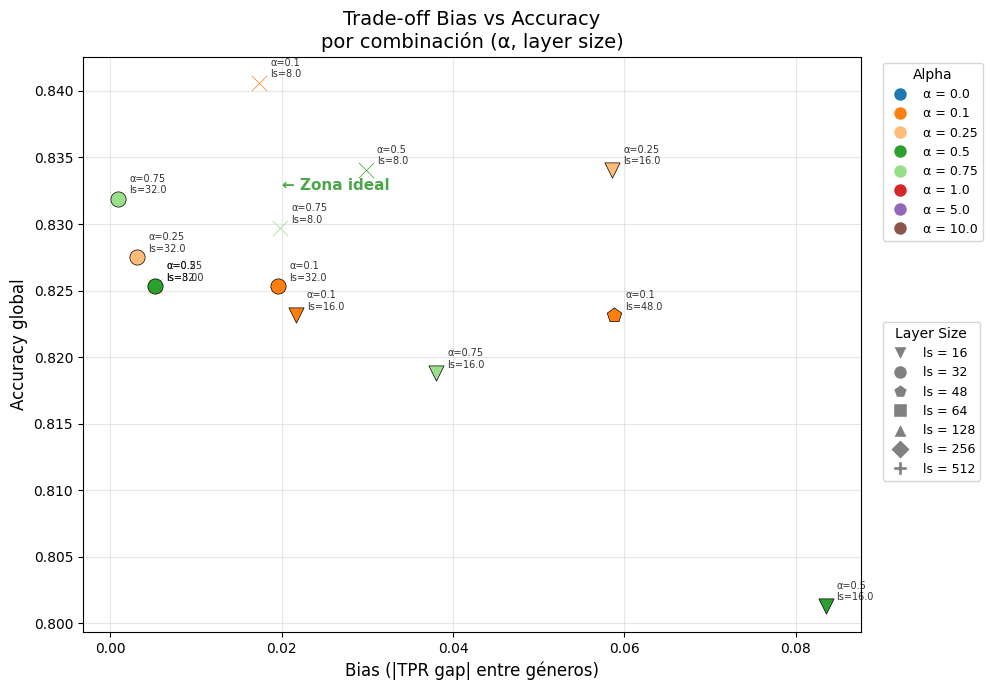

Gráfico guardado en bias_vs_accuracy.png


In [6]:
fig, ax = plt.subplots(figsize=(10, 7))

# Colores por alpha, marcadores por ls
alpha_colors = {0.0: '#1f77b4', 0.1: '#ff7f0e', 0.25: '#ffbb78', 0.5: '#2ca02c',
                0.75: '#98df8a', 1.0: '#d62728', 5.0: '#9467bd', 10.0: '#8c564b'}
ls_markers = {16: 'v', 32: 'o', 48: 'p', 64: 's', 128: '^', 256: 'D', 512: 'P'}

for _, row in df_results.iterrows():
    a = row['alpha']
    l = row['ls']
    ax.scatter(
        row['tpr_gap'], row['accuracy'],
        color=alpha_colors.get(a, 'gray'),
        marker=ls_markers.get(l, 'x'),
        s=120, edgecolors='black', linewidths=0.5, zorder=5
    )
    # Etiquetar cada punto
    ax.annotate(
        f'α={a}\nls={l}',
        (row['tpr_gap'], row['accuracy']),
        textcoords='offset points', xytext=(8, 4),
        fontsize=7, alpha=0.8
    )

# Leyenda para alpha (colores)
from matplotlib.lines import Line2D
legend_alpha = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=10,
                       label=f'α = {a}') for a, c in alpha_colors.items()]
legend_ls = [Line2D([0], [0], marker=m, color='w', markerfacecolor='gray', markersize=10,
                    label=f'ls = {l}') for l, m in ls_markers.items()]

leg1 = ax.legend(handles=legend_alpha, title='Alpha', loc='upper left',
                 bbox_to_anchor=(1.02, 1), fontsize=9)
ax.add_artist(leg1)
ax.legend(handles=legend_ls, title='Layer Size', loc='upper left',
          bbox_to_anchor=(1.02, 0.55), fontsize=9)

ax.set_xlabel('Bias (|TPR gap| entre géneros)', fontsize=12)
ax.set_ylabel('Accuracy global', fontsize=12)
ax.set_title('Trade-off Bias vs Accuracy\npor combinación (α, layer size)', fontsize=14)
ax.grid(True, alpha=0.3)

# Zona ideal
ax.annotate('← Zona ideal', xy=(0.02, ax.get_ylim()[1] - 0.01),
            fontsize=11, color='green', fontweight='bold', alpha=0.7)

plt.tight_layout()
plt.savefig('bias_vs_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gráfico guardado en bias_vs_accuracy.png")

## 5. Gráficos adicionales

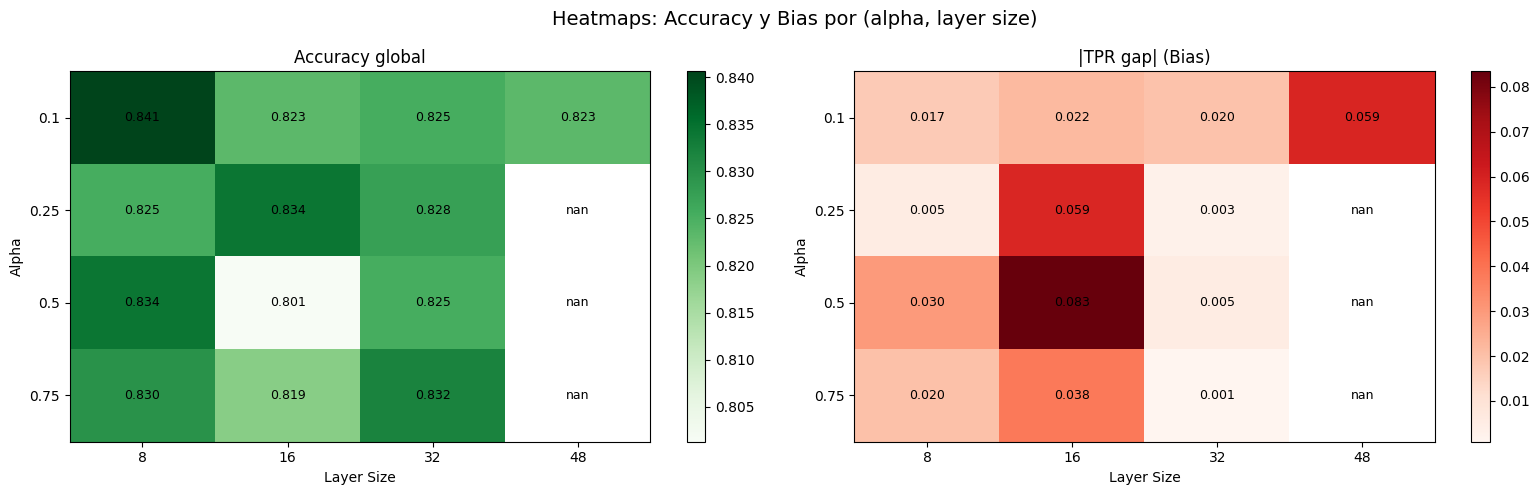

Heatmaps guardados en heatmaps_acc_bias.png


In [7]:
# --- Heatmap: Accuracy por (alpha, ls) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

pivot_acc = df_results.pivot(index='alpha', columns='ls', values='accuracy')
pivot_bias = df_results.pivot(index='alpha', columns='ls', values='tpr_gap')

im1 = axes[0].imshow(pivot_acc.values, cmap='Greens', aspect='auto')
axes[0].set_xticks(range(len(pivot_acc.columns)))
axes[0].set_xticklabels(pivot_acc.columns)
axes[0].set_yticks(range(len(pivot_acc.index)))
axes[0].set_yticklabels(pivot_acc.index)
axes[0].set_xlabel('Layer Size')
axes[0].set_ylabel('Alpha')
axes[0].set_title('Accuracy global')
for i in range(len(pivot_acc.index)):
    for j in range(len(pivot_acc.columns)):
        axes[0].text(j, i, f'{pivot_acc.values[i, j]:.3f}',
                     ha='center', va='center', fontsize=9)
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(pivot_bias.values, cmap='Reds', aspect='auto')
axes[1].set_xticks(range(len(pivot_bias.columns)))
axes[1].set_xticklabels(pivot_bias.columns)
axes[1].set_yticks(range(len(pivot_bias.index)))
axes[1].set_yticklabels(pivot_bias.index)
axes[1].set_xlabel('Layer Size')
axes[1].set_ylabel('Alpha')
axes[1].set_title('|TPR gap| (Bias)')
for i in range(len(pivot_bias.index)):
    for j in range(len(pivot_bias.columns)):
        axes[1].text(j, i, f'{pivot_bias.values[i, j]:.3f}',
                     ha='center', va='center', fontsize=9)
plt.colorbar(im2, ax=axes[1])

plt.suptitle('Heatmaps: Accuracy y Bias por (alpha, layer size)', fontsize=14)
plt.tight_layout()
plt.savefig('heatmaps_acc_bias.png', dpi=150, bbox_inches='tight')
plt.show()
print("Heatmaps guardados en heatmaps_acc_bias.png")

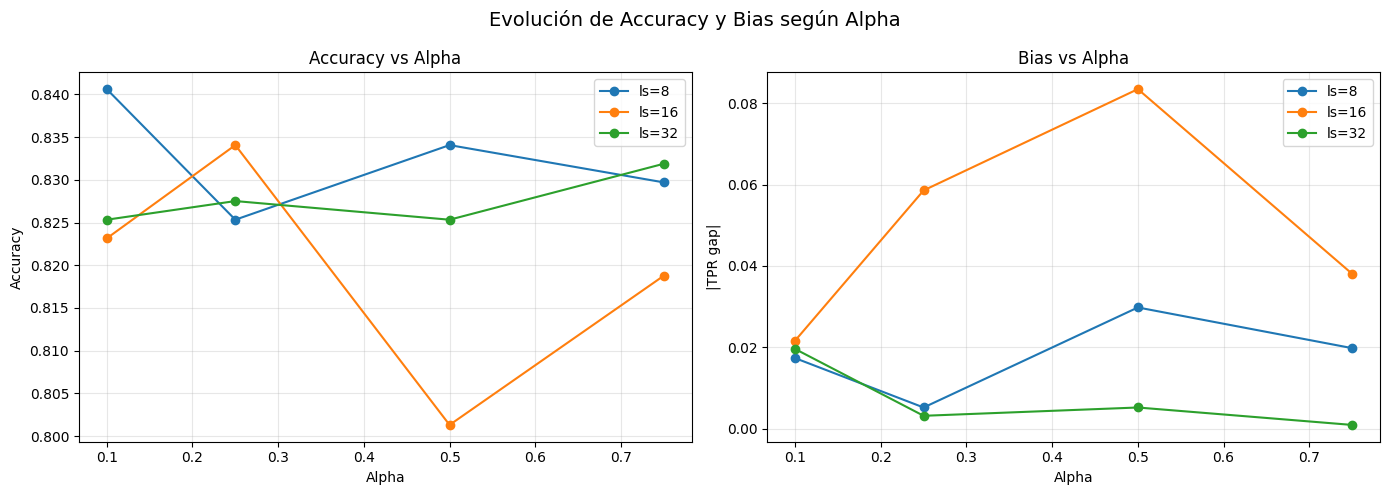

In [8]:
# --- Curvas: Accuracy y Bias vs Alpha, para cada layer size ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ls in layer_sizes:
    subset = df_results[df_results['ls'] == ls].sort_values('alpha')
    axes[0].plot(subset['alpha'], subset['accuracy'], marker='o', label=f'ls={ls}')
    axes[1].plot(subset['alpha'], subset['tpr_gap'], marker='o', label=f'ls={ls}')

axes[0].set_xlabel('Alpha')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs Alpha')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel('Alpha')
axes[1].set_ylabel('|TPR gap|')
axes[1].set_title('Bias vs Alpha')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Evolución de Accuracy y Bias según Alpha', fontsize=14)
plt.tight_layout()
plt.savefig('curves_alpha.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Presència del sexe a l'última capa per model

`layer_6` és la capa intermèdia (`interm`) — la penúltima del model, just abans del classificador final.
Un AUC de **0.5** indica que el gènere és **no predible** des d'aquesta representació (ideal fairness).
Un AUC proper a **1.0** indica que la informació de sexe hi és present.

Es mostren: heatmap per (alpha, ls), corbes vs alpha i scatter tridimensional Bias–Accuracy–GenderAUC.

/tmp/ipykernel_21828/2431064563.py:45: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axes[2].scatter(


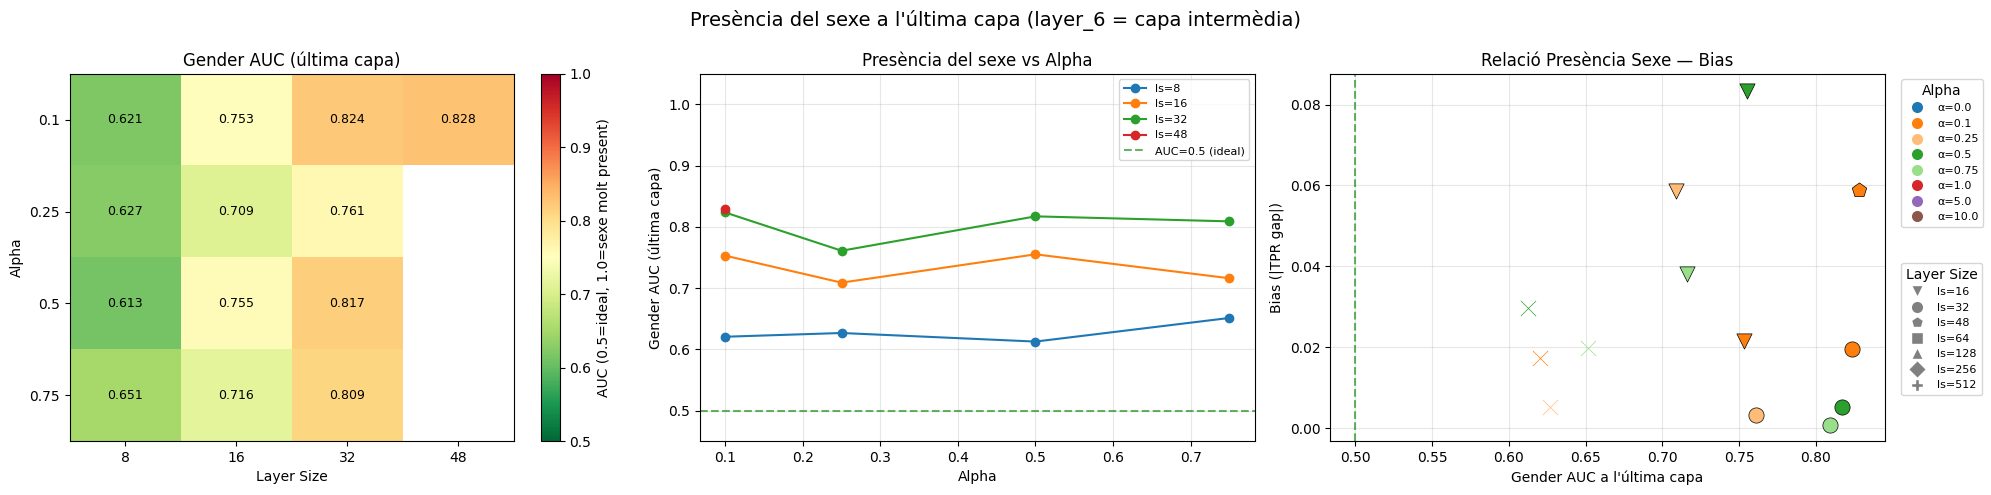

Gràfic guardat en gender_presence_last_layer.png


In [9]:
df_gender = df_results.dropna(subset=['gender_auc_last_layer']).copy()

if df_gender.empty:
    print("No hi ha dades de 'gender_auc_last_layer' als resultats.")
    print("Torna a executar el sweep (cel·la 3) per generar-les.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    # --- 1. Heatmap: Gender AUC a l'última capa per (alpha, ls) ---
    pivot_gauc = df_gender.pivot(index='alpha', columns='ls', values='gender_auc_last_layer')
    im = axes[0].imshow(pivot_gauc.values, cmap='RdYlGn_r', aspect='auto', vmin=0.5, vmax=1.0)
    axes[0].set_xticks(range(len(pivot_gauc.columns)))
    axes[0].set_xticklabels(pivot_gauc.columns)
    axes[0].set_yticks(range(len(pivot_gauc.index)))
    axes[0].set_yticklabels(pivot_gauc.index)
    axes[0].set_xlabel('Layer Size')
    axes[0].set_ylabel('Alpha')
    axes[0].set_title('Gender AUC (última capa)')
    for i in range(len(pivot_gauc.index)):
        for j in range(len(pivot_gauc.columns)):
            val = pivot_gauc.values[i, j]
            if not np.isnan(val):
                axes[0].text(j, i, f'{val:.3f}', ha='center', va='center', fontsize=9)
    plt.colorbar(im, ax=axes[0], label='AUC (0.5=ideal, 1.0=sexe molt present)')

    # --- 2. Corbes: Gender AUC vs Alpha per cada layer size ---
    for ls in sorted(df_gender['ls'].unique()):
        subset = df_gender[df_gender['ls'] == ls].sort_values('alpha')
        axes[1].plot(subset['alpha'], subset['gender_auc_last_layer'], marker='o', label=f'ls={ls}')
    axes[1].axhline(0.5, color='green', linestyle='--', alpha=0.6, label='AUC=0.5 (ideal)')
    axes[1].set_xlabel('Alpha')
    axes[1].set_ylabel('Gender AUC (última capa)')
    axes[1].set_title('Presència del sexe vs Alpha')
    axes[1].set_ylim(0.45, 1.05)
    axes[1].legend(fontsize=8)
    axes[1].grid(True, alpha=0.3)

    # --- 3. Scatter: Bias vs Gender AUC, color=alpha ---
    alpha_colors = {0.0: '#1f77b4', 0.1: '#ff7f0e', 0.25: '#ffbb78', 0.5: '#2ca02c',
                    0.75: '#98df8a', 1.0: '#d62728', 5.0: '#9467bd', 10.0: '#8c564b'}
    ls_markers = {16: 'v', 32: 'o', 48: 'p', 64: 's', 128: '^', 256: 'D', 512: 'P'}

    for _, row in df_gender.iterrows():
        a, l = row['alpha'], row['ls']
        axes[2].scatter(
            row['gender_auc_last_layer'], row['tpr_gap'],
            color=alpha_colors.get(a, 'gray'),
            marker=ls_markers.get(l, 'x'),
            s=120, edgecolors='black', linewidths=0.5, zorder=5
        )
    axes[2].axvline(0.5, color='green', linestyle='--', alpha=0.6, label='Gender AUC=0.5 (ideal)')
    axes[2].set_xlabel('Gender AUC a l\'última capa')
    axes[2].set_ylabel('Bias (|TPR gap|)')
    axes[2].set_title('Relació Presència Sexe — Bias')
    axes[2].grid(True, alpha=0.3)

    from matplotlib.lines import Line2D
    legend_alpha = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c,
                           markersize=9, label=f'α={a}') for a, c in alpha_colors.items()]
    legend_ls = [Line2D([0], [0], marker=m, color='w', markerfacecolor='gray',
                        markersize=9, label=f'ls={l}') for l, m in ls_markers.items()]
    leg1 = axes[2].legend(handles=legend_alpha, title='Alpha', loc='upper left',
                          bbox_to_anchor=(1.02, 1), fontsize=8)
    axes[2].add_artist(leg1)
    axes[2].legend(handles=legend_ls, title='Layer Size', loc='upper left',
                   bbox_to_anchor=(1.02, 0.5), fontsize=8)

    plt.suptitle('Presència del sexe a l\'última capa (layer_6 = capa intermèdia)', fontsize=14)
    plt.tight_layout()
    plt.savefig('gender_presence_last_layer.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Gràfic guardat en gender_presence_last_layer.png")